# 01 — Data Understanding

**Kenapa notebook ini ada?** Sebelum menyentuh model, kita harus tahu bentuk datanya.
Semua keputusan berikutnya (metrik apa, model apa, preprocessing apa) bergantung pada
jawaban lima pertanyaan di bawah. Melewatkan tahap ini adalah penyebab nomor satu
project machine learning yang hasilnya tidak bisa dijelaskan.

**Lima pertanyaan yang harus dijawab:**

1. Berapa baris dan kolom? Apa saja isinya?
2. Tipe datanya apa? Mana angka, mana teks?
3. Ada data kotor (kosong, duplikat, tipe salah)?
4. Targetnya apa, dan seimbang atau tidak?
5. Fitur mana yang kelihatannya berhubungan dengan target?

## 0. Persiapan

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)

# notebook dijalankan dari folder notebooks/, jadi naik satu level ke root project
BASE = Path.cwd()
if not (BASE / "data").exists():
    BASE = BASE.parent
print("root project:", BASE)

RAW = BASE / "data" / "raw" / "telco_churn.csv"
df = pd.read_csv(RAW)
print("file:", RAW.name)

root project: c:\Users\53\Documents\data sains\machine learning\project ML Supervised
file: telco_churn.csv


## 1. Bentuk data

In [2]:
print("jumlah baris :", df.shape[0])
print("jumlah kolom :", df.shape[1])
print()
print("Daftar kolom:")
for i, c in enumerate(df.columns, 1):
    print(f"  {i:2d}. {c}")

jumlah baris : 7043
jumlah kolom : 21

Daftar kolom:
   1. customerID
   2. gender
   3. SeniorCitizen
   4. Partner
   5. Dependents
   6. tenure
   7. PhoneService
   8. MultipleLines
   9. InternetService
  10. OnlineSecurity
  11. OnlineBackup
  12. DeviceProtection
  13. TechSupport
  14. StreamingTV
  15. StreamingMovies
  16. Contract
  17. PaperlessBilling
  18. PaymentMethod
  19. MonthlyCharges
  20. TotalCharges
  21. Churn


In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Setiap baris = **satu pelanggan**. Kolom terakhir (`Churn`) adalah jawaban yang mau
diprediksi. Sisanya adalah "pertanyaan" yang boleh dipakai model.

Satu kolom yang perlu dicurigai sejak awal: `customerID` — isinya kode unik per
pelanggan, bukan sifat pelanggan. Nanti kolom ini dibuang.

## 2. Tipe data

In [4]:
ringkas = df.dtypes.astype(str).value_counts()
print("Ringkasan tipe data:")
print(ringkas.to_string())
print()
print("Kolom numerik :", df.select_dtypes(include=np.number).columns.tolist())
print()
print("Kolom teks    :", df.select_dtypes(include="str").columns.tolist())

Ringkasan tipe data:
str        18
int64       2
float64     1

Kolom numerik : ['SeniorCitizen', 'tenure', 'MonthlyCharges']

Kolom teks    : ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']


Ternyata hanya **4 kolom** yang berupa angka (`SeniorCitizen`, `tenure`,
`MonthlyCharges`, `TotalCharges`), sisanya teks. Ini penting: model scikit-learn
**tidak bisa** menerima teks, jadi 15 kolom teks harus diubah jadi angka pada
notebook 03.

## 3. Kualitas data — cari masalahnya sekarang

In [5]:
print("Jumlah nilai kosong (NaN) per kolom:")
kosong = df.isna().sum()
print("  total:", int(kosong.sum()))
print()
print("Baris duplikat penuh :", int(df.duplicated().sum()))
print("customerID unik      :", df["customerID"].nunique(), "dari", len(df), "baris")

Jumlah nilai kosong (NaN) per kolom:
  total: 0

Baris duplikat penuh : 0
customerID unik      : 7043 dari 7043 baris


In [6]:
# Kolom TotalCharges terlihat angka, tapi cek tipenya
print("tipe TotalCharges:", df["TotalCharges"].dtype)
print("contoh 5 nilai  :", df["TotalCharges"].head().tolist())

# cari yang isinya kosong (spasi, bukan NaN)
blank = df["TotalCharges"].astype(str).str.strip() == ""
print("\nTotalCharges yang kosong (isi spasi):", int(blank.sum()))
print("tenure dari baris tersebut:", sorted(df.loc[blank, "tenure"].unique().tolist()))
df.loc[blank, ["tenure", "MonthlyCharges", "TotalCharges"]].head()

tipe TotalCharges: str
contoh 5 nilai  : ['29.85', '1889.5', '108.15', '1840.75', '151.65']

TotalCharges yang kosong (isi spasi): 11
tenure dari baris tersebut: [0]


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,
753,0,20.25,
936,0,80.85,
1082,0,25.75,
1340,0,56.05,


**Tiga masalah ditemukan:**

| # | Masalah | Dampak kalau dibiarkan |
|---|---|---|
| 1 | `TotalCharges` bertipe **teks**, berisi 11 nilai kosong (spasi) | Error saat scaling/model |
| 2 | `customerID` unik untuk setiap baris | Model menghafal ID, bukan belajar pola |
| 3 | `Churn` masih `Yes`/`No` | Target harus angka 1/0 |

Kabar baiknya: **tidak ada NaN asli dan tidak ada duplikat**. Jadi cleaning-nya
ringan, tidak perlu imputasi rumit.

11 baris kosong itu semuanya punya `tenure = 0` — artinya pelanggan baru daftar
dan belum pernah ditagih. Masuk akal kalau `TotalCharges`-nya kosong.

## 4. Target: seimbang atau tidak?

In [7]:
print(df["Churn"].value_counts().to_string())
print()
print((df["Churn"].value_counts(normalize=True) * 100).round(2).to_string(), "%")

Churn
No     5174
Yes    1869

Churn
No     73.46
Yes    26.54 %


C:\Users\53\AppData\Local\Temp\ipykernel_9264\1127279185.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x="Churn", palette=["#4c72b0", "#dd8452"])


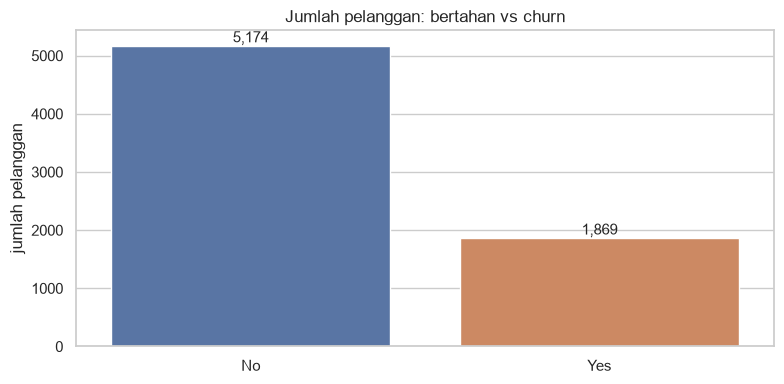

In [8]:
ax = sns.countplot(data=df, x="Churn", palette=["#4c72b0", "#dd8452"])
ax.set_title("Jumlah pelanggan: bertahan vs churn")
ax.set_xlabel("")
ax.set_ylabel("jumlah pelanggan")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=11)
plt.tight_layout()
plt.show()

**26,5% churn vs 73,5% bertahan.** Ini disebut **class imbalance** (kelas tidak
seimbang), walaupun masih tergolong ringan.

Kenapa ini penting? Karena model yang selalu menjawab "tidak churn" akan dapat
**akurasi 73,5%** tanpa belajar apa pun. Artinya angka akurasi di dataset ini
menipu. Itu sebabnya project ini memakai **recall** sebagai metrik utama — akan
dibahas di notebook 05.

## 5. Statistik kolom numerik

In [9]:
df[["SeniorCitizen", "tenure", "MonthlyCharges"]].describe().round(2)

,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


In [10]:
print("Rentang nilai:")
print(f"  tenure         : {df['tenure'].min()} - {df['tenure'].max()} bulan (median {df['tenure'].median():.0f})")
tc = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(f"  MonthlyCharges : {df['MonthlyCharges'].min():.2f} - {df['MonthlyCharges'].max():.2f} (median {df['MonthlyCharges'].median():.2f})")
print(f"  TotalCharges   : {tc.min():.2f} - {tc.max():.2f}")

Rentang nilai:
  tenure         : 0 - 72 bulan (median 29)
  MonthlyCharges : 18.25 - 118.75 (median 70.35)
  TotalCharges   : 18.80 - 8684.80


Tidak ada outlier ekstrem. `tenure` 0–72 bulan (6 tahun), `MonthlyCharges`
18–119 dolar. Skalanya cukup jauh berbeda (`tenure` puluhan, `MonthlyCharges`
puluhan, `TotalCharges` ribuan) → nanti KNN dan Logistic Regression perlu
**scaling**, sedangkan Random Forest tidak.

## 6. Isi tiap kolom teks

In [11]:
for c in df.select_dtypes(include="str").columns:
    if c in ("customerID", "TotalCharges"):
        continue
    nilai = df[c].value_counts().to_dict()
    print(f"{c:18s} ({df[c].nunique()} nilai) -> {nilai}")

gender             (2 nilai) -> {'Male': 3555, 'Female': 3488}
Partner            (2 nilai) -> {'No': 3641, 'Yes': 3402}
Dependents         (2 nilai) -> {'No': 4933, 'Yes': 2110}
PhoneService       (2 nilai) -> {'Yes': 6361, 'No': 682}
MultipleLines      (3 nilai) -> {'No': 3390, 'Yes': 2971, 'No phone service': 682}
InternetService    (3 nilai) -> {'Fiber optic': 3096, 'DSL': 2421, 'No': 1526}
OnlineSecurity     (3 nilai) -> {'No': 3498, 'Yes': 2019, 'No internet service': 1526}
OnlineBackup       (3 nilai) -> {'No': 3088, 'Yes': 2429, 'No internet service': 1526}
DeviceProtection   (3 nilai) -> {'No': 3095, 'Yes': 2422, 'No internet service': 1526}
TechSupport        (3 nilai) -> {'No': 3473, 'Yes': 2044, 'No internet service': 1526}
StreamingTV        (3 nilai) -> {'No': 2810, 'Yes': 2707, 'No internet service': 1526}
StreamingMovies    (3 nilai) -> {'No': 2785, 'Yes': 2732, 'No internet service': 1526}
Contract           (3 nilai) -> {'Month-to-month': 3875, 'Two year': 1695, 'One 

Perhatikan pola yang muncul: banyak kolom punya nilai **`"No internet service"`**
selain `"No"`. Keduanya sebenarnya berarti "tidak punya layanan itu", tapi ditulis
beda karena pelanggannya tidak berlangganan internet sama sekali.

Kita **biarkan apa adanya** (tidak digabung) supaya informasi "tidak punya internet"
tetap bisa dipakai model. Keputusan ini dicatat di README bagian *Keputusan penting*.

## 7. Ringkasan notebook 01

| Fakta | Nilai |
|---|---|
| Bentuk data | 7.043 pelanggan × 21 kolom |
| Kolom numerik | 4 (`SeniorCitizen`, `tenure`, `MonthlyCharges`, `TotalCharges`) |
| Kolom teks | 15 (setelah `customerID` dan `Churn` dipisahkan) |
| Nilai kosong asli | 0 |
| `TotalCharges` bermasalah | 11 baris berisi spasi, semuanya `tenure = 0` |
| Duplikat | 0 |
| Churn | 1.869 (26,54%) |
| Tenure | 0–72 bulan, median 29 |
| Tagihan bulanan | $18,25–$118,75, median $70,35 |

**Yang belum terjawab:** *kenapa* pelanggan pergi? Notebook 01 hanya memastikan
datanya layak dipakai. Notebook 02 merapikan, notebook 04 mencari jawabannya.